# Validating a Credit Scorecard When the Sample Is Small: the South German Credit Data with Bootstrap and DeLong Intervals, Calibration and Stability Tests, a Cost-Based Cut-Off, Naive Bayes and KNN Challengers, Swap Sets and Fair-Lending Checks

A scorecard is validated before it is used and again every year after. Independent validators ask four questions:
- Does it rank good and bad borrowers (*discrimination*)?
- Do its probabilities match what happens (*calibration*)?
- Is the population it scores still the one it was built on (*stability*)?
- Does it lead to sensible decisions at its cut-off, fairly across groups (*use*)?

They also build *challenger* models to see whether something simpler or more flexible would do better.

Most textbook examples use tens of thousands of loans. Many real portfolios are small: a regional lender, an SME or microfinance book, a new product. With a few hundred defaults, every validation statistic has wide error bars, and a validator who reads point estimates as facts will reject good models and accept bad ones. This notebook validates a scorecard on the **South German Credit** data, 1,000 consumer loans of which 300 went bad, the corrected 2020 release of the classic German credit dataset. It reports every statistic with its uncertainty:

- **Development.** A weight-of-evidence (WoE) scorecard with monotone coarse classing, information values and points scaled to 20 points per doubling of the odds.
- **Discrimination.** Gini and AUC with DeLong and bootstrap confidence intervals, the KS statistic with its critical value, CAP curves, and the spread of Gini across 50 repeated cross-validation splits.
- **Calibration.** Score bands against observed bad rates, Jeffreys intervals per band, Hosmer–Lemeshow and calibration-in-the-large.
- **Stability.** PSI and CSI between development and validation samples, compared with the PSI that sampling noise alone produces at this sample size.
- **Challengers.** Naive Bayes, k-nearest neighbours, LightGBM and a dummy-coded logistic regression against the scorecard: DeLong tests, and *swap sets* (who would be accepted by one model and rejected by the other, and how those borrowers behaved).
- **Use.** A cut-off chosen with the dataset's own cost matrix (accepting a bad borrower costs five times as much as rejecting a good one), and fair-lending checks: adverse impact ratios and equal-opportunity gaps for foreign workers and for applicants under 25. These characteristics are kept out of the model.
- **Verdict.** A red/amber/green summary in the form a validation report would use.

**Data.** South German Credit (UCI Machine Learning Repository, dataset 573; Grömping 2019).

**Methods.** WoE coarse classing and information value, logistic regression, points scaling, DeLong test, bootstrap, KS with critical value, CAP and accuracy ratio, Jeffreys intervals, Hosmer–Lemeshow, PSI/CSI with simulated null distributions, categorical naive Bayes, k-nearest neighbours, LightGBM, swap-set analysis, cost-based cut-off, adverse impact ratio and equal-opportunity difference.

**Key output.** A validated scorecard with its points table; every performance statistic with an interval; challengers compared by DeLong test and swap sets; a cost-optimal cut-off; fair-lending ratios; a validation verdict.

## 1. What a validator checks

| Area | Question | Statistic | Typical threshold |
|---|---|---|---|
| Discrimination | Does the score rank bads above goods? | Gini = 2·AUC − 1, KS | Gini > 40% for application scorecards; interval matters more than point |
| Calibration | Do predicted PDs match observed bad rates? | Bad rate by band, Jeffreys / binomial tests, Hosmer–Lemeshow | No band rejected at 5% after multiple-testing care |
| Stability | Has the population moved? | PSI = Σ (*a*<sub>*i*</sub> − *e*<sub>*i*</sub>) ln(*a*<sub>*i*</sub>/*e*<sub>*i*</sub>), CSI per characteristic | PSI < 0.10 stable, 0.10–0.25 watch, > 0.25 shift |
| Benchmarking | Would another model do better? | Challenger AUC, DeLong test, swap sets | Significant and material difference |
| Use | Are decisions sensible and fair? | Expected cost at the cut-off, adverse impact ratio | AIR > 0.8 (the four-fifths rule) |

The PSI thresholds were set with large samples in mind. With a few hundred loans, sampling noise alone produces PSI values that can approach them, which is checked below.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile

import lightgbm as lgb
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    train_test_split,
)
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
UCI_URL = "https://archive.ics.uci.edu/static/public/573/south+german+credit+update.zip"
VAL_SIZE = 0.3
# 600 points at odds of 50 good : 1 bad, 20 points to double the odds
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
COST_BAD_ACCEPTED, COST_GOOD_REJECTED = 5, 1  # the dataset's cost matrix
N_BOOT, N_REPEAT = 1000, 10
# used only to test fairness, never as model inputs
PROTECTED = ["foreign_worker", "age_under_25"]

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-10


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

The 2020 release corrects coding errors found in the widely circulated 1994 version. The target is `credit_risk`: 0 = bad, 1 = good, recoded here as **bad = 1**. Three characteristics are kept out of the model:
- **Personal status and sex:** it mixes the two.
- **Foreign worker:** a protected characteristic, used only for the fairness tests.
- **Telephone:** not a legitimate credit factor today.

Age stays in the model, as it does in most scorecards where the law allows it, and its effect on approval is tested.

In [3]:
def fetch():
    r = requests.get(UCI_URL, timeout=120)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        return pd.read_csv(z.open("SouthGermanCredit.asc"), sep=" ")


RAW = cached("south_german_credit", fetch, max_age_hours=24 * 365)
NAMES = [
    "status",
    "duration",
    "credit_history",
    "purpose",
    "amount",
    "savings",
    "employment_duration",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "present_residence",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "number_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "credit_risk",
]
DF = RAW.copy()
DF.columns = NAMES
DF["bad"] = 1 - DF.credit_risk
# 1 = yes
DF["foreign_worker"] = (DF.foreign_worker == 1).astype(int)
DF["age_under_25"] = (DF.age < 25).astype(int)
NUMERIC = ["duration", "amount", "age"]
CATEG = [
    "status",
    "credit_history",
    "purpose",
    "savings",
    "employment_duration",
    "installment_rate",
    "other_debtors",
    "present_residence",
    "property",
    "other_installment_plans",
    "housing",
    "number_credits",
    "job",
    "people_liable",
]
DEV, VAL = train_test_split(
    DF, test_size=VAL_SIZE, stratify=DF.bad, random_state=SEED
)
print(
    f"{len(DF)} loans, {DF.bad.sum()} bad ({DF.bad.mean():.0%}); development"
    f" {len(DEV)} ({DEV.bad.sum()} bad), validation {len(VAL)}"
    f" ({VAL.bad.sum()} bad)"
)
print(
    f"Foreign workers: {DF.foreign_worker.sum()}"
    f" ({DF.foreign_worker.mean():.1%}); applicants under 25:"
    f" {DF.age_under_25.sum()}"
)

1000 loans, 300 bad (30%); development 700 (210 bad), validation 300 (90 bad)
Foreign workers: 37 (3.7%); applicants under 25: 150


## 4. Development: WoE coarse classing, information value and the points table

**Numerical characteristics** (duration, amount, age) are cut at the quintiles of the development sample. Adjacent bins are then merged until the bad rate is monotone. **Categorical characteristics** with fewer than 30 development loans in a category are pooled with their closest neighbour in bad rate.

Each class gets WoE = ln(share of goods / share of bads), with 0.5 added to empty cells. The **information value** IV = Σ (good share − bad share) · WoE measures each characteristic's strength. Characteristics with IV above 0.02 enter a logistic regression on their WoE values.

Points per class follow from scaling the log-odds: Score = Offset + Factor · ln(odds), with Factor = PDO / ln 2 and Offset = 600 − Factor · ln 50.

In [4]:
def woe_table(x, y):
    t = pd.crosstab(x, y).reindex(columns=[0, 1], fill_value=0) + 0.5
    good, bad = t[0] / t[0].sum(), t[1] / t[1].sum()
    w = np.log(good / bad)
    return pd.DataFrame({
        "n": t.sum(axis=1) - 1,
        "bad rate": (t[1] - 0.5) / (t.sum(axis=1) - 1),
        "WoE": w,
        "IV part": (good - bad) * w,
    })


def bin_numeric(x, y, q=5):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    while True:
        b = pd.cut(x, edges)
        br = y.groupby(b, observed=False).mean().values
        sign = np.sign(np.corrcoef(x, y)[0, 1]) or 1
        diffs = np.diff(br) * sign
        if len(br) <= 2 or (diffs >= 0).all():
            return edges
        i = int(np.argmin(diffs))
        edges = np.delete(edges, i + 1)


def bin_categ(x, y, min_n=30):
    mapping = {c: c for c in x.unique()}
    while True:
        cls = x.map(mapping)
        n = cls.value_counts()
        small = n[n < min_n]
        if small.empty:
            return mapping
        s = small.index[0]
        br = y.groupby(cls).mean()
        other = (br.drop(s) - br[s]).abs().idxmin()
        for k, v in mapping.items():
            if v == s:
                mapping[k] = other


BINS = {}
for c in NUMERIC:
    BINS[c] = ("num", bin_numeric(DEV[c], DEV.bad))
for c in CATEG:
    BINS[c] = ("cat", bin_categ(DEV[c], DEV.bad))


def classes(frame, c):
    kind, spec = BINS[c]
    if kind == "num":
        return pd.cut(frame[c], spec).astype(str)
    return frame[c].map(spec).fillna(frame[c]).astype(str)


WOE, IV = {}, {}
for c in NUMERIC + CATEG:
    t = woe_table(classes(DEV, c), DEV.bad)
    WOE[c], IV[c] = t, t["IV part"].sum()
IV = pd.Series(IV).sort_values(ascending=False)
SELECTED = list(IV[IV > 0.02].index)


def woe_frame(frame):
    return pd.DataFrame(
        {
            c: classes(frame, c).map(WOE[c]["WoE"]).fillna(0.0)
            for c in SELECTED
        },
        index=frame.index,
    )


W_DEV, W_VAL = woe_frame(DEV), woe_frame(VAL)
# practically unpenalised
SC = LogisticRegression(C=1e6, max_iter=5000).fit(W_DEV, DEV.bad)
FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)


def points_table():
    rows = []
    n = len(SELECTED)
    for coef, c in zip(SC.coef_[0], SELECTED):
        for cl, r in WOE[c].iterrows():
            pts = -(coef * r.WoE + SC.intercept_[0] / n) * FACTOR + OFFSET / n
            rows.append((c, cl, int(r.n), r["bad rate"], r.WoE, round(pts)))
    return pd.DataFrame(
        rows,
        columns=[
            "characteristic",
            "class",
            "dev loans",
            "bad rate",
            "WoE",
            "points",
        ],
    )


POINTS = points_table()


def score_points(frame):
    w = woe_frame(frame)
    logit = SC.intercept_[0] + w.values @ SC.coef_[0]
    # score (higher = safer) and PD
    return OFFSET - FACTOR * logit, 1 / (1 + np.exp(-logit))


S_DEV, PD_DEV = score_points(DEV)
S_VAL, PD_VAL = score_points(VAL)
print("Information value:", ", ".join(f"{k} {v:.3f}" for k, v in IV.items()))
print(
    f"{len(SELECTED)} characteristics selected (IV > 0.02); scores range"
    f" {S_DEV.min():.0f}–{S_DEV.max():.0f} on development"
)
POINTS.style.format({"bad rate": "{:.1%}", "WoE": "{:+.2f}"}).hide(
    axis="index"
)

Information value: status 0.559, savings 0.300, duration 0.288, purpose 0.238, credit_history 0.233, property 0.101, employment_duration 0.092, age 0.084, amount 0.078, housing 0.072, other_debtors 0.039, other_installment_plans 0.032, installment_rate 0.020, present_residence 0.010, job 0.009, number_credits 0.009, people_liable 0.005
12 characteristics selected (IV > 0.02); scores range 413–625 on development


characteristic,class,dev loans,bad rate,WoE,points
status,1,186,47.8%,-0.76,26
status,2,188,39.4%,-0.41,34
status,3,50,22.0%,+0.39,51
status,4,276,13.0%,+1.04,65
savings,1,416,37.7%,-0.34,34
savings,2,78,32.1%,-0.10,40
savings,3,40,15.0%,+0.83,64
savings,4,35,8.6%,+1.39,79
savings,5,131,14.5%,+0.91,66
duration,"(-inf, 15.0]",314,19.1%,+0.59,58


## 5. Discrimination with its uncertainty

**AUC uncertainty.** The **DeLong** method gives the variance of an AUC (and of the difference between two correlated AUCs) from the structural components of the Mann–Whitney statistic. The **bootstrap** resamples loans 1,000 times. **Repeated cross-validation** refits the whole scorecard on 50 different splits, which shows how much of the validation Gini depends on which 300 loans happen to be in the validation sample.

**KS.** The KS statistic is compared with its 5% critical value, 1.36 · √((*n*<sub>good</sub> + *n*<sub>bad</sub>) / (*n*<sub>good</sub> · *n*<sub>bad</sub>)).

In [5]:
def delong(y, *scores):
    """
    AUCs and their covariance matrix (DeLong et al. 1988), for one or more
    scores on the same loans.
    """
    y = np.asarray(y)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    aucs, V10, V01 = [], [], []
    for s in scores:
        s = np.asarray(s)
        sp, sn = s[pos][:, None], s[neg][None, :]
        psi = (sp > sn) + 0.5 * (sp == sn)
        V10.append(psi.mean(axis=1))
        V01.append(psi.mean(axis=0))
        aucs.append(psi.mean())
    S10, S01 = np.cov(np.array(V10)), np.cov(np.array(V01))
    cov = np.atleast_2d(S10) / len(pos) + np.atleast_2d(S01) / len(neg)
    return np.array(aucs), cov


def ks(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    nb, ng = y.sum(), len(y) - y.sum()
    return (tpr - fpr).max(), 1.36 * np.sqrt((nb + ng) / (nb * ng))


def boot_gini(y, s, n=N_BOOT):
    y, s = np.asarray(y), np.asarray(s)
    out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        out.append(2 * roc_auc_score(y[i], s[i]) - 1)
    return np.percentile(out, [2.5, 97.5])


rows = []
for lab, y, pdv in [
    ("development", DEV.bad.values, PD_DEV),
    ("validation", VAL.bad.values, PD_VAL),
]:
    a, c = delong(y, pdv)
    se = np.sqrt(c[0, 0])
    k, kcrit = ks(y, pdv)
    lo, hi = boot_gini(y, pdv)
    rows.append((
        lab,
        len(y),
        int(y.sum()),
        2 * a[0] - 1,
        2 * (a[0] - 1.96 * se) - 1,
        2 * (a[0] + 1.96 * se) - 1,
        lo,
        hi,
        k,
        kcrit,
    ))
DISC = pd.DataFrame(
    rows,
    columns=[
        "sample",
        "loans",
        "bads",
        "Gini",
        "DeLong 95% low",
        "DeLong 95% high",
        "bootstrap 95% low",
        "bootstrap 95% high",
        "KS",
        "KS 5% critical",
    ],
)


def fit_scorecard_pd(dev, val, drop=()):
    """
    refit the whole scorecard (binning, WoE, logistic) on dev and return
    validation PDs: used by repeated cross-validation.
    """
    bins = {
        c: ("num", bin_numeric(dev[c], dev.bad))
        for c in NUMERIC
        if c not in drop
    } | {
        c: ("cat", bin_categ(dev[c], dev.bad)) for c in CATEG if c not in drop
    }

    def cls(frame, c):
        kind, spec = bins[c]
        return (
            pd.cut(frame[c], spec).astype(str)
            if kind == "num"
            else frame[c].map(spec).fillna(frame[c]).astype(str)
        )

    woe = {c: woe_table(cls(dev, c), dev.bad) for c in bins}
    sel = [c for c in bins if woe[c]["IV part"].sum() > 0.02]
    wf = lambda f: pd.DataFrame(
        {c: cls(f, c).map(woe[c]["WoE"]).fillna(0.0) for c in sel},
        index=f.index,
    )
    m = LogisticRegression(C=1e6, max_iter=5000).fit(wf(dev), dev.bad)
    return m.predict_proba(wf(val))[:, 1]


cv_gini = []
for tr, te in RepeatedStratifiedKFold(
    n_splits=5, n_repeats=N_REPEAT, random_state=SEED
).split(DF, DF.bad):
    d_, v_ = DF.iloc[tr], DF.iloc[te]
    cv_gini.append(2 * roc_auc_score(v_.bad, fit_scorecard_pd(d_, v_)) - 1)
cv_gini = np.array(cv_gini)
print(
    f"Repeated 5-fold CV ({len(cv_gini)} fits of 200 held-out loans): Gini"
    f" mean {cv_gini.mean():.3f}, 5th–95th percentile"
    f" {np.percentile(cv_gini, 5):.3f}–{np.percentile(cv_gini, 95):.3f}"
)
DISC.style.format({c: "{:.3f}" for c in DISC.columns[3:]})

Repeated 5-fold CV (50 fits of 200 held-out loans): Gini mean 0.561, 5th–95th percentile 0.466–0.649


,sample,loans,bads,Gini,DeLong 95% low,DeLong 95% high,bootstrap 95% low,bootstrap 95% high,KS,KS 5% critical
0,development,700,210,0.638,0.572,0.704,0.567,0.701,0.520,0.112
1,validation,300,90,0.537,0.420,0.654,0.419,0.660,0.463,0.171


## 6. Calibration

Validation loans are grouped into five score bands, cut at the development quintiles. In each band the average predicted PD is compared with the observed bad rate, using the **Jeffreys** interval (the Beta(*d* + ½, *n* − *d* + ½) posterior), which behaves well with small counts.
- **Hosmer–Lemeshow** tests the bands jointly.
- **Calibration in the large** compares the total number of bads with the sum of the PDs.

In [6]:
edges_band = np.quantile(S_DEV, [0, 0.2, 0.4, 0.6, 0.8, 1])
edges_band[0], edges_band[-1] = -np.inf, np.inf
band = pd.cut(
    S_VAL, edges_band, labels=["E (riskiest)", "D", "C", "B", "A (safest)"]
)
CAL = (
    pd.DataFrame({"band": band, "pd": PD_VAL, "bad": VAL.bad.values})
    .groupby("band", observed=True)
    .agg(
        loans=("bad", "size"),
        bads=("bad", "sum"),
        predicted_pd=("pd", "mean"),
        observed=("bad", "mean"),
    )
)
CAL["Jeffreys 95% low"] = stats.beta.ppf(
    0.025, CAL.bads + 0.5, CAL.loans - CAL.bads + 0.5
)
CAL["Jeffreys 95% high"] = stats.beta.ppf(
    0.975, CAL.bads + 0.5, CAL.loans - CAL.bads + 0.5
)
CAL["PD inside interval"] = (CAL.predicted_pd >= CAL["Jeffreys 95% low"]) & (
    CAL.predicted_pd <= CAL["Jeffreys 95% high"]
)
hl = (
    ((CAL.bads - CAL.loans * CAL.predicted_pd) ** 2)
    / (CAL.loans * CAL.predicted_pd * (1 - CAL.predicted_pd))
).sum()
HL_P = 1 - stats.chi2.cdf(hl, len(CAL) - 2)
z_large = (VAL.bad.sum() - PD_VAL.sum()) / np.sqrt(
    (PD_VAL * (1 - PD_VAL)).sum()
)
print(
    f"Hosmer–Lemeshow (5 bands): {hl:.2f}, p = {HL_P:.3f}; calibration in the"
    f" large: {VAL.bad.sum()} bads observed vs {PD_VAL.sum():.1f} predicted, z"
    f" = {z_large:+.2f}; Brier {np.mean((PD_VAL - VAL.bad.values) ** 2):.4f}"
)
CAL.style.format({
    "predicted_pd": "{:.1%}",
    "observed": "{:.1%}",
    "Jeffreys 95% low": "{:.1%}",
    "Jeffreys 95% high": "{:.1%}",
})

Hosmer–Lemeshow (5 bands): 7.81, p = 0.050; calibration in the large: 90 bads observed vs 92.8 predicted, z = -0.41; Brier 0.1710


,loans,bads,predicted_pd,observed,Jeffreys 95% low,Jeffreys 95% high,PD inside interval
band,,,,,,,
E (riskiest),64,37,67.4%,57.8%,45.6%,69.3%,True
D,56,27,42.1%,48.2%,35.5%,61.1%,True
C,72,16,24.0%,22.2%,13.8%,32.8%,True
B,57,5,11.5%,8.8%,3.4%,18.2%,True
A (safest),51,5,4.3%,9.8%,3.8%,20.2%,True


## 7. Stability: PSI and CSI, against sampling noise

The PSI between the development and validation score distributions should be near zero, because both samples come from the same population. The question is *how* near. The notebook simulates its null distribution, the PSI between two random samples of 700 and 300 drawn from the same 1,000 loans, 2,000 times. The same is done for each characteristic's CSI.

In [7]:
def psi(expected, actual, edges):
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-4
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-4
    return float(((a - e) * np.log(a / e)).sum())


edges10 = np.quantile(S_DEV, np.linspace(0, 1, 11))
edges10[0], edges10[-1] = -np.inf, np.inf
PSI_OBS = psi(S_DEV, S_VAL, edges10)
S_ALL = np.r_[S_DEV, S_VAL]
null = []
for _ in range(2000):
    p_ = rng.permutation(len(S_ALL))
    null.append(psi(S_ALL[p_[: len(S_DEV)]], S_ALL[p_[len(S_DEV) :]], edges10))
null = np.array(null)
csi_rows = []
for c in SELECTED:
    cd, cv = classes(DEV, c), classes(VAL, c)
    levels = sorted(set(cd) | set(cv))
    e = cd.value_counts(normalize=True).reindex(levels, fill_value=0) + 1e-4
    a = cv.value_counts(normalize=True).reindex(levels, fill_value=0) + 1e-4
    allc = pd.concat([cd, cv]).values
    nul = []
    for _ in range(500):
        p_ = rng.permutation(len(allc))
        e_ = (
            pd.Series(allc[p_[: len(cd)]])
            .value_counts(normalize=True)
            .reindex(levels, fill_value=0)
            + 1e-4
        )
        a_ = (
            pd.Series(allc[p_[len(cd) :]])
            .value_counts(normalize=True)
            .reindex(levels, fill_value=0)
            + 1e-4
        )
        nul.append(((a_ - e_) * np.log(a_ / e_)).sum())
    csi_rows.append((
        c,
        len(levels),
        float(((a - e) * np.log(a / e)).sum()),
        np.percentile(nul, 95),
    ))
CSI = pd.DataFrame(
    csi_rows,
    columns=["characteristic", "classes", "CSI", "95th pct under no shift"],
)
print(
    f"Score PSI development vs validation: {PSI_OBS:.4f}; under no shift, mean"
    f" {null.mean():.4f}, 95th pct {np.percentile(null, 95):.4f}, 99th"
    f" {np.percentile(null, 99):.4f}; P(PSI > 0.10 by chance) ="
    f" {(null > 0.10).mean():.2%}"
)
print(
    "PSI from sampling noise alone at other sample sizes (development 700 vs a"
    " validation sample of n, 10 bands, mean / 95th pct):"
)
for n_ in [50, 100, 200]:
    sim = [psi(S_DEV, rng.choice(S_ALL, n_), edges10) for _ in range(1000)]
    print(f"  n = {n_}: {np.mean(sim):.3f} / {np.percentile(sim, 95):.3f}")
CSI.style.format({"CSI": "{:.4f}", "95th pct under no shift": "{:.4f}"}).hide(
    axis="index"
)

Score PSI development vs validation: 0.0184; under no shift, mean 0.0424, 95th pct 0.0793, 99th 0.1006; P(PSI > 0.10 by chance) = 1.25%
PSI from sampling noise alone at other sample sizes (development 700 vs a validation sample of n, 10 bands, mean / 95th pct):
  n = 50: 0.222 / 0.495
  n = 100: 0.099 / 0.192
  n = 200: 0.047 / 0.088


characteristic,classes,CSI,95th pct under no shift
status,4,0.0168,0.0345
savings,5,0.0173,0.0436
duration,4,0.0353,0.0388
purpose,6,0.0292,0.0546
credit_history,4,0.0026,0.0346
property,4,0.0248,0.0379
employment_duration,5,0.0149,0.0438
age,5,0.0193,0.0454
amount,3,0.0156,0.0264
housing,3,0.0093,0.0321


## 8. Challengers and swap sets

Four challengers are fitted on the same development sample, using the same characteristics (protected attributes excluded):
- **Categorical naive Bayes** on the coarse classes.
- **k-nearest neighbours** on one-hot classes plus standardised numerical values, with *k* chosen by cross-validation.
- **LightGBM** with shallow trees.
- **A logistic regression on dummy variables**, the most common alternative to WoE coding.

The champion is compared with each challenger on the validation sample by a DeLong test of the AUC difference. The *swap set* is then built at an approval rate of 70%: the loans accepted by one model and rejected by the other. If the challenger's swap-ins have fewer bads than its swap-outs, it makes better decisions where the two models disagree.

In [8]:
FEAT = NUMERIC + CATEG
ohe = OneHotEncoder(handle_unknown="ignore").fit(DEV[CATEG].astype(str))
snum = StandardScaler().fit(DEV[NUMERIC])
Xk = lambda f: np.hstack(
    [ohe.transform(f[CATEG].astype(str)).toarray(), snum.transform(f[NUMERIC])]
)
cls_codes = {
    c: {v: i for i, v in enumerate(sorted(set(classes(DF, c))))} for c in FEAT
}
Xnb = lambda f: np.column_stack(
    [classes(f, c).map(cls_codes[c]).values for c in FEAT]
)
CH = {}
CH["Naive Bayes"] = CategoricalNB(
    alpha=1.0, min_categories=[len(cls_codes[c]) for c in FEAT]
).fit(Xnb(DEV), DEV.bad)
best_k, best_auc = None, -1
for k in [15, 25, 41, 61, 81]:
    aucs = []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(
        DEV, DEV.bad
    ):
        m = KNeighborsClassifier(k).fit(Xk(DEV.iloc[tr]), DEV.bad.iloc[tr])
        aucs.append(
            roc_auc_score(
                DEV.bad.iloc[te], m.predict_proba(Xk(DEV.iloc[te]))[:, 1]
            )
        )
    if np.mean(aucs) > best_auc:
        best_k, best_auc = k, np.mean(aucs)
CH[f"KNN (k = {best_k})"] = KNeighborsClassifier(best_k).fit(Xk(DEV), DEV.bad)
gbm_dev = DEV[FEAT].copy()
CH["LightGBM"] = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    random_state=SEED,
    verbose=-1,
).fit(gbm_dev, DEV.bad)
CH["Logistic (dummies)"] = LogisticRegression(C=0.5, max_iter=5000).fit(
    Xk(DEV), DEV.bad
)


def ch_pd(name, f):
    m = CH[name]
    if name == "Naive Bayes":
        return m.predict_proba(Xnb(f))[:, 1]
    if name == "LightGBM":
        return m.predict_proba(f[FEAT])[:, 1]
    return m.predict_proba(Xk(f))[:, 1]


P_VAL = {"Scorecard (champion)": PD_VAL} | {n: ch_pd(n, VAL) for n in CH}
yv = VAL.bad.values
rows = []
for n, p in P_VAL.items():
    a, c = delong(yv, PD_VAL, p)
    diff = a[1] - a[0]
    se = (
        np.sqrt(c[0, 0] + c[1, 1] - 2 * c[0, 1])
        if n != "Scorecard (champion)"
        else np.nan
    )
    pval = (
        2 * (1 - stats.norm.cdf(abs(diff) / se))
        if n != "Scorecard (champion)"
        else np.nan
    )
    cut_c, cut_n = np.quantile(PD_VAL, 0.7), np.quantile(p, 0.7)
    acc_c, acc_n = PD_VAL <= cut_c, p <= cut_n
    swap_in, swap_out = acc_n & ~acc_c, acc_c & ~acc_n
    rows.append((
        n,
        2 * a[1] - 1,
        2 * diff,
        pval,
        int(swap_in.sum()),
        yv[swap_in].mean() if swap_in.any() else np.nan,
        yv[swap_out].mean() if swap_out.any() else np.nan,
        yv[acc_n].mean(),
    ))
BENCH = pd.DataFrame(
    rows,
    columns=[
        "model",
        "Gini (validation)",
        "Gini − champion",
        "DeLong p",
        "swap-ins (= swap-outs)",
        "bad rate of swap-ins",
        "bad rate of swap-outs",
        "bad rate of accepted (70%)",
    ],
)
BENCH.style.format(
    {
        "Gini (validation)": "{:.3f}",
        "Gini − champion": "{:+.3f}",
        "DeLong p": "{:.3f}",
        "bad rate of swap-ins": "{:.1%}",
        "bad rate of swap-outs": "{:.1%}",
        "bad rate of accepted (70%)": "{:.1%}",
    },
    na_rep="–",
).hide(axis="index")

model,Gini (validation),Gini − champion,DeLong p,swap-ins (= swap-outs),bad rate of swap-ins,bad rate of swap-outs,bad rate of accepted (70%)
Scorecard (champion),0.537,+0.000,–,0,–,–,18.1%
Naive Bayes,0.566,+0.029,0.092,9,66.7%,44.4%,19.0%
KNN (k = 25),0.469,-0.068,0.112,35,48.6%,44.4%,20.7%
LightGBM,0.550,+0.013,0.714,16,37.5%,37.5%,18.1%
Logistic (dummies),0.519,-0.018,0.511,19,52.6%,36.8%,19.5%


## 9. Cut-off and fair lending

The cut-off minimises the expected cost per applicant on the development sample: 5 × bads accepted + 1 × goods rejected, divided by the number of applicants. The cut-off is then applied unchanged to the validation sample.

At that cut-off, the approval rates of protected groups are compared with those of the reference group:
- the **adverse impact ratio** (AIR), the approval rate of the protected group divided by that of the reference group, with values under 0.8 calling for review under the four-fifths rule;
- the **equal-opportunity difference**, the gap in approval rates among applicants who turned out *good*.

Both are computed on all 1,000 loans scored out of fold, to have enough foreign workers to say anything. Because age is a characteristic of the scorecard, the test is repeated with a scorecard refitted *without* age, at the same approval rate, to separate the effect of age itself from that of the characteristics correlated with it.

In [9]:
def expected_cost(y, pdv, cut):
    acc = pdv <= cut
    return (
        COST_BAD_ACCEPTED * (acc & (y == 1)).sum()
        + COST_GOOD_REJECTED * (~acc & (y == 0)).sum()
    ) / len(y)


grid = np.unique(np.quantile(PD_DEV, np.linspace(0.05, 0.99, 120)))
costs = np.array([expected_cost(DEV.bad.values, PD_DEV, c) for c in grid])
CUT = grid[costs.argmin()]
CUT_SCORE = OFFSET - FACTOR * np.log(CUT / (1 - CUT))
theory = COST_GOOD_REJECTED / (COST_GOOD_REJECTED + COST_BAD_ACCEPTED)
CUTOFF = pd.DataFrame({
    s: {
        "approval rate": (p <= CUT).mean(),
        "bad rate of approved": y[p <= CUT].mean(),
        "bads rejected (share of bads)": (p > CUT)[y == 1].mean(),
        "expected cost per applicant": expected_cost(y, p, CUT),
        "cost of approving everyone": COST_BAD_ACCEPTED * y.mean(),
    }
    for s, y, p in [
        ("development", DEV.bad.values, PD_DEV),
        ("validation", yv, PD_VAL),
    ]
}).T
# out-of-fold PDs for all 1,000 loans, for the fairness tests
OOF, OOF_NOAGE = np.zeros(len(DF)), np.zeros(len(DF))
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(
    DF, DF.bad
):
    OOF[te] = fit_scorecard_pd(DF.iloc[tr], DF.iloc[te])
    OOF_NOAGE[te] = fit_scorecard_pd(DF.iloc[tr], DF.iloc[te], drop=("age",))
FAIR = []
for variant, oof in [("scorecard", OOF), ("scorecard without age", OOF_NOAGE)]:
    # same approval rate for both variants
    cut_v = np.quantile(oof, (OOF <= CUT).mean())
    acc_all = oof <= cut_v
    for g, lab in [
        ("foreign_worker", "foreign workers vs others"),
        ("age_under_25", "under 25 vs 25 and over"),
    ]:
        prot, ref = DF[g].values == 1, DF[g].values == 0
        good = DF.bad.values == 0
        air = acc_all[prot].mean() / acc_all[ref].mean()
        eo = acc_all[prot & good].mean() - acc_all[ref & good].mean()
        tab = [
            [acc_all[prot].sum(), (~acc_all[prot]).sum()],
            [acc_all[ref].sum(), (~acc_all[ref]).sum()],
        ]
        FAIR.append((
            variant,
            lab,
            int(prot.sum()),
            2 * roc_auc_score(DF.bad, oof) - 1,
            acc_all[prot].mean(),
            acc_all[ref].mean(),
            air,
            eo,
            DF.bad[prot].mean(),
            DF.bad[ref].mean(),
            stats.fisher_exact(tab)[1],
        ))
FAIR = pd.DataFrame(
    FAIR,
    columns=[
        "model",
        "comparison",
        "protected n",
        "Gini (out of fold)",
        "approval protected",
        "approval reference",
        "adverse impact ratio",
        "equal-opportunity difference",
        "bad rate protected",
        "bad rate reference",
        "Fisher p (approval)",
    ],
)
print(
    f"Cost-optimal cut-off: PD ≤ {CUT:.1%} (score ≥ {CUT_SCORE:.0f}); with"
    f" perfectly calibrated PDs the theory gives PD ≤ {theory:.1%}"
)
display(
    CUTOFF.style.format("{:.1%}").format(
        "{:.3f}",
        subset=["expected cost per applicant", "cost of approving everyone"],
    )
)
FAIR.style.format({
    "Gini (out of fold)": "{:.3f}",
    "approval protected": "{:.1%}",
    "approval reference": "{:.1%}",
    "adverse impact ratio": "{:.2f}",
    "equal-opportunity difference": "{:+.1%}",
    "bad rate protected": "{:.1%}",
    "bad rate reference": "{:.1%}",
    "Fisher p (approval)": "{:.3f}",
}).hide(axis="index")

Cost-optimal cut-off: PD ≤ 14.7% (score ≥ 538); with perfectly calibrated PDs the theory gives PD ≤ 16.7%


,approval rate,bad rate of approved,bads rejected (share of bads),expected cost per applicant,cost of approving everyone
development,38.1%,6.4%,91.9%,0.464,1.500
validation,34.0%,9.8%,88.9%,0.560,1.500


model,comparison,protected n,Gini (out of fold),approval protected,approval reference,adverse impact ratio,equal-opportunity difference,bad rate protected,bad rate reference,Fisher p (approval)
scorecard,foreign workers vs others,37,0.551,45.9%,36.8%,1.25,+3.1%,10.8%,30.7%,0.298
scorecard,under 25 vs 25 and over,150,0.551,17.3%,40.6%,0.43,-24.4%,41.3%,28.0%,0.000
scorecard without age,foreign workers vs others,37,0.550,43.2%,36.9%,1.17,+0.7%,10.8%,30.7%,0.489
scorecard without age,under 25 vs 25 and over,150,0.550,27.3%,38.8%,0.70,-10.5%,41.3%,28.0%,0.008


## 10. Validation verdict

In [10]:
v = DISC.set_index("sample").loc["validation"]
rag = lambda ok, warn: "GREEN" if ok else ("AMBER" if warn else "RED")
best_ch = (
    BENCH.iloc[1:].sort_values("Gini (validation)", ascending=False).iloc[0]
)
VERDICT = pd.DataFrame(
    [
        (
            "Discrimination",
            (
                f"validation Gini {v.Gini:.2f} (DeLong 95%:"
                f" {v['DeLong 95% low']:.2f}–{v['DeLong 95% high']:.2f})"
            ),
            "lower bound > 0.40",
            rag(v["DeLong 95% low"] > 0.40, v.Gini > 0.40),
        ),
        (
            "Discrimination",
            f"KS {v.KS:.2f} vs critical {v['KS 5% critical']:.2f}",
            "KS > critical",
            rag(v.KS > v["KS 5% critical"], False),
        ),
        (
            "Calibration",
            (
                f"{int(CAL['PD inside interval'].sum())}/{len(CAL)} bands"
                f" inside Jeffreys interval; HL p = {HL_P:.2f}; z ="
                f" {z_large:+.2f}"
            ),
            "all bands inside, HL p > 0.05",
            rag(CAL["PD inside interval"].all() and HL_P > 0.05, HL_P > 0.01),
        ),
        (
            "Stability",
            (
                f"PSI {PSI_OBS:.3f} (no-shift 95th pct"
                f" {np.percentile(null, 95):.3f}); max CSI {CSI.CSI.max():.3f}"
            ),
            "PSI within sampling noise",
            rag(PSI_OBS <= np.percentile(null, 95), PSI_OBS < 0.10),
        ),
        (
            "Benchmarking",
            (
                f"best challenger {best_ch.model}: Gini"
                f" {best_ch['Gini (validation)']:.2f}, DeLong p"
                f" {best_ch['DeLong p']:.2f}"
            ),
            "no significantly better challenger",
            rag(
                not (
                    best_ch["Gini − champion"] > 0
                    and best_ch["DeLong p"] < 0.05
                ),
                best_ch["DeLong p"] >= 0.01,
            ),
        ),
        (
            "Use: cut-off",
            (
                "validation cost"
                f" {CUTOFF.loc['validation', 'expected cost per applicant']:.3f}"
                f" vs {CUTOFF.loc['validation', 'cost of approving everyone']:.3f}"
                " approving all"
            ),
            "cost below the no-model policy",
            rag(
                CUTOFF.loc["validation", "expected cost per applicant"]
                < CUTOFF.loc["validation", "cost of approving everyone"],
                False,
            ),
        ),
        (
            "Use: fair lending",
            "; ".join(
                f"{r.comparison.split(' vs')[0]} AIR"
                f" {r['adverse impact ratio']:.2f}"
                for _, r in FAIR[FAIR.model == "scorecard"].iterrows()
            ),
            "AIR ≥ 0.80",
            rag(
                (
                    FAIR[FAIR.model == "scorecard"]["adverse impact ratio"]
                    >= 0.8
                ).all(),
                (
                    FAIR[FAIR.model == "scorecard"]["adverse impact ratio"]
                    >= 0.7
                ).all(),
            ),
        ),
    ],
    columns=["area", "result", "criterion", "status"],
)
VERDICT.style.hide(axis="index")

area,result,criterion,status
Discrimination,validation Gini 0.54 (DeLong 95%: 0.42–0.65),lower bound > 0.40,GREEN
Discrimination,KS 0.46 vs critical 0.17,KS > critical,GREEN
Calibration,5/5 bands inside Jeffreys interval; HL p = 0.05; z = -0.41,"all bands inside, HL p > 0.05",GREEN
Stability,PSI 0.018 (no-shift 95th pct 0.079); max CSI 0.035,PSI within sampling noise,GREEN
Benchmarking,"best challenger Naive Bayes: Gini 0.57, DeLong p 0.09",no significantly better challenger,GREEN
Use: cut-off,validation cost 0.560 vs 1.500 approving all,cost below the no-model policy,GREEN
Use: fair lending,foreign workers AIR 1.25; under 25 AIR 0.43,AIR ≥ 0.80,RED


## 11. Charts and dashboard

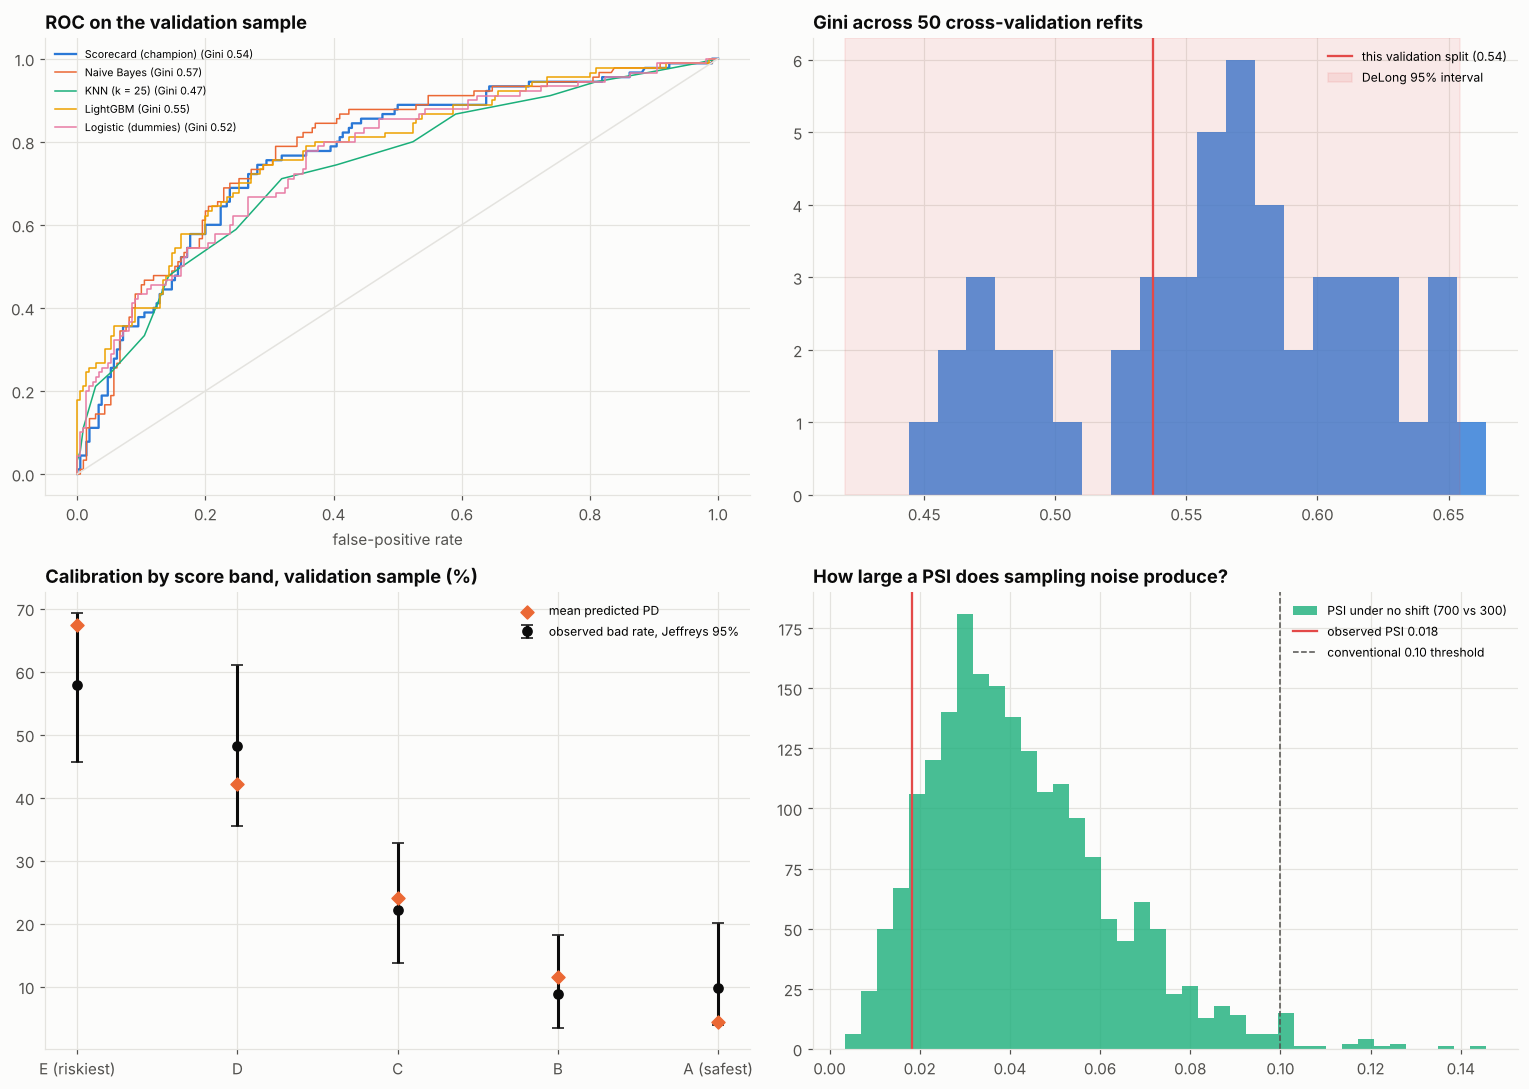

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for j, (n, p) in enumerate(P_VAL.items()):
    fpr, tpr, _ = roc_curve(yv, p)
    a.plot(
        fpr,
        tpr,
        color=PALETTE[j],
        lw=1.5 if j == 0 else 1,
        label=f"{n} (Gini {2 * roc_auc_score(yv, p) - 1:.2f})",
    )
a.plot([0, 1], [0, 1], color=GRID, lw=1)
a.set_title("ROC on the validation sample")
a.set_xlabel("false-positive rate")
a.legend(fontsize=7)
a = ax[0, 1]
a.hist(cv_gini, bins=20, color=PALETTE[0], alpha=0.8)
a.axvline(
    v.Gini,
    color=PALETTE[7],
    lw=1.5,
    label=f"this validation split ({v.Gini:.2f})",
)
a.axvspan(
    v["DeLong 95% low"],
    v["DeLong 95% high"],
    color=PALETTE[7],
    alpha=0.1,
    label="DeLong 95% interval",
)
a.set_title("Gini across 50 cross-validation refits")
a.legend(fontsize=8)
a = ax[1, 0]
x = np.arange(len(CAL))
a.errorbar(
    x,
    CAL.observed * 100,
    yerr=[
        (CAL.observed - CAL["Jeffreys 95% low"]) * 100,
        (CAL["Jeffreys 95% high"] - CAL.observed) * 100,
    ],
    fmt="o",
    color=INK,
    capsize=4,
    label="observed bad rate, Jeffreys 95%",
)
a.scatter(
    x,
    CAL.predicted_pd * 100,
    color=PALETTE[1],
    marker="D",
    zorder=3,
    label="mean predicted PD",
)
a.set_xticks(x, CAL.index)
a.set_title("Calibration by score band, validation sample (%)")
a.legend(fontsize=8)
a = ax[1, 1]
a.hist(
    null,
    bins=40,
    color=PALETTE[2],
    alpha=0.8,
    label="PSI under no shift (700 vs 300)",
)
a.axvline(
    PSI_OBS, color=PALETTE[7], lw=1.5, label=f"observed PSI {PSI_OBS:.3f}"
)
a.axvline(
    0.10, color=INK_2, ls="--", lw=1, label="conventional 0.10 threshold"
)
a.set_title("How large a PSI does sampling noise produce?")
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_scorecard_validation_overview")
plt.show()

In [12]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Expected cost per applicant by PD cut-off (development)",
        "Gini on validation: champion vs challengers",
    ),
)
dash.add_trace(
    go.Scatter(
        x=grid, y=costs, name="expected cost", line=dict(color=PALETTE[0])
    ),
    1,
    1,
)
dash.add_vline(x=CUT, line_color=PALETTE[7], row=1, col=1)
dash.add_trace(
    go.Bar(
        x=BENCH.model,
        y=BENCH["Gini (validation)"],
        marker_color=PALETTE[1],
        showlegend=False,
    ),
    1,
    2,
)
dash.update_layout(
    height=520,
    width=1400,
    template="simple_white",
    title="Scorecard validation on a small sample",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 12. Reading the results and limitations

*The data are a fixed public file and every random step is seeded, so the figures are reproducible.*

**The scorecard.** The 1,000 loans include 300 bads and are split 700 / 300 for development and validation.
- **Characteristics:** twelve pass the IV > 0.02 filter. The strongest are the checking-account status (IV 0.56), savings (0.30), duration (0.29), purpose (0.24) and credit history (0.23).
- **Points:** scores range from about 410 to 625. A customer with no checking account gets 26 points for that characteristic; one with a salary account over 200 DM gets 65.

**Discrimination: good, with intervals as wide as the debate about it.**

| Sample | Gini | DeLong 95% | Bootstrap 95% | KS (critical) |
|---|---|---|---|---|
| Development (700, 210 bads) | 0.64 | 0.57–0.70 | 0.57–0.70 | 0.52 (0.11) |
| Validation (300, 90 bads) | 0.54 | 0.42–0.65 | 0.42–0.66 | 0.46 (0.17) |

- **How wide the interval is.** The validation Gini is 10 points below development, a drop that would alarm many validators. Its 95% interval, though, spans 23 points, and refitting the scorecard on 50 cross-validation splits gives Ginis from 0.47 to 0.65 (5th–95th percentile, mean 0.56).
- **What that means for reviews.** With 90 bads, a Gini difference of less than about 0.1 between two years or two models is not evidence of anything. The DeLong interval and the bootstrap agree closely, so the cheap analytical interval is enough.

**Calibration: acceptable.**
- **By band:** all five score bands have their mean predicted PD inside the Jeffreys interval of the observed bad rate.
- **In total:** 90 bads were observed against 92.8 predicted (z = −0.41).
- **Hosmer–Lemeshow:** p = 0.050, on the line, driven by the riskiest band (67% predicted, 58% observed) and the safest (4% predicted, 10% observed). With 51–72 loans per band, no band rejects.

**Stability: the PSI thresholds are too loose for small samples, and too tight for very small ones.**
- **This split:** the PSI between development and validation is 0.018, well inside the no-shift 95th percentile of 0.079. No characteristic's CSI exceeds its own no-shift benchmark.
- **Pure noise:** sampling noise alone produces a mean PSI of 0.10 for a 100-loan sample and 0.22 for a 50-loan sample. That is the "watch" and "shift" zones of the conventional 0.10 / 0.25 thresholds without any shift at all.
- **What to do:** a small-portfolio validator should compare PSI with its simulated null distribution, not with fixed thresholds.

**Challengers: none is significantly better.**

| Model | Validation Gini | Difference vs scorecard | DeLong p |
|---|---|---|---|
| Naive Bayes | 0.566 | +0.029 | 0.09 |
| LightGBM | 0.550 | +0.013 | 0.71 |
| Logistic on dummies | 0.519 | −0.018 | 0.51 |
| KNN (*k* = 25) | 0.469 | −0.068 | 0.11 |

- **Naive Bayes nearly matches the scorecard.** Its WoE-like structure fits small categorical data well.
- **KNN suffers most** from the small sample and the mixed variable types.
- **Swap sets confirm the scorecard.** At a 70% approval rate, Naive Bayes would swap in 9 loans of which 67% went bad, against 44% of the 9 it would swap out. The scorecard makes the better calls where the two disagree.

**The cut-off and its cost.**
- **Where it falls.** The 5:1 cost matrix puts the optimal cut-off at PD ≤ 14.7% (a score of 538 or more), close to the theoretical 1/(1+5) = 16.7% for a calibrated model.
- **What it costs.** It approves only 34–38% of applicants, with a 6–10% bad rate among the approved. The expected cost falls from 1.50 per applicant (approve everyone) to 0.56 on validation.
- **The trade-off.** A lender with a softer cost ratio would approve far more; the cost matrix, not the model, sets the approval rate.

**Fair lending: the scorecard fails for young applicants, because of age itself.**
- **Under 25.** At the cut-off, applicants under 25 are approved at 17% against 41% for older applicants: an adverse impact ratio of 0.43, far below 0.8. Among applicants who turned out *good*, the under-25s were approved 24 points less often.
- **Without age.** Refitting the scorecard without age costs nothing in accuracy (out-of-fold Gini 0.550 against 0.551). At the same approval rate it lifts the adverse impact ratio to 0.70 and halves the equal-opportunity gap. The rest of the gap comes from characteristics that tend to go with youth, such as shorter employment and smaller savings, and from a genuinely higher bad rate (41% against 28%).
- **Foreign workers** are approved more often than others (AIR 1.25), but there are only 37 of them.
- **The validation recommendation:** remove age, or justify it under the applicable fair-lending rules, and monitor the young-applicant AIR.

**Verdict.** Six areas pass and fair lending fails:

| Area | Status | Basis |
|---|---|---|
| Discrimination | Green | DeLong lower bound 0.42 > 0.40 |
| Calibration | Green | All bands inside their Jeffreys intervals |
| Stability | Green | PSI within sampling noise |
| Benchmarking | Green | No challenger significantly better |
| Cut-off | Green | Expected cost below the approve-all policy |
| Fair lending | Red | Under-25 AIR 0.43 |

**Limitations.**
- **Data:** a historical German sample from the 1970s, with an oversampled 30% bad rate, so the absolute PDs do not describe any current portfolio. Personal status and sex are mixed in one variable and cannot be tested separately.
- **Sample size:** the fairness test for foreign workers rests on 37 loans.

In [13]:
POINTS.to_csv(OUT_DIR / "scorecard_points.csv", index=False)
IV.to_frame("IV").to_csv(OUT_DIR / "information_values.csv")
DISC.to_csv(OUT_DIR / "discrimination.csv", index=False)
CAL.to_csv(OUT_DIR / "calibration_bands.csv")
CSI.to_csv(OUT_DIR / "characteristic_stability.csv", index=False)
BENCH.to_csv(OUT_DIR / "challengers_and_swap_sets.csv", index=False)
CUTOFF.to_csv(OUT_DIR / "cutoff.csv")
FAIR.to_csv(OUT_DIR / "fair_lending.csv", index=False)
VERDICT.to_csv(OUT_DIR / "validation_verdict.csv", index=False)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_scorecard_validation_overview.png, calibration_bands.csv, challengers_and_swap_sets.csv, characteristic_stability.csv, cutoff.csv, dashboard.html, dashboard.png, discrimination.csv, fair_lending.csv, information_values.csv, scorecard_points.csv, validation_verdict.csv


## References

- Brown, L. D., Cai, T. T., & DasGupta, A. (2001). Interval estimation for a binomial proportion. *Statistical Science*, 16(2), 101–133. https://doi.org/10.1214/ss/1009213286
- DeLong, E. R., DeLong, D. M., & Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics*, 44(3), 837–845. https://doi.org/10.2307/2531595
- Grömping, U. (2019). *South German credit data: Correcting a widely used data set* (Reports in Mathematics, Physics and Chemistry, Report 4/2019). Beuth University of Applied Sciences Berlin.
- Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. In *Advances in Neural Information Processing Systems 29* (pp. 3315–3323).
- Hosmer, D. W., & Lemeshow, S. (1980). Goodness of fit tests for the multiple logistic regression model. *Communications in Statistics – Theory and Methods*, 9(10), 1043–1069. https://doi.org/10.1080/03610928008827941
- Siddiqi, N. (2017). *Intelligent credit scoring: Building and implementing better credit risk scorecards* (2nd ed.). Wiley.
- UCI Machine Learning Repository. *South German Credit (UPDATE)* (dataset 573). https://archive.ics.uci.edu/dataset/573/south+german+credit+update
- U.S. Equal Employment Opportunity Commission et al. (1978). Uniform guidelines on employee selection procedures, 29 C.F.R. § 1607.4(D) (the four-fifths rule).